# Credit Card Fraud Detection - Machine Learning & Analytics Pipeline

## Project Overview
This project presents an end-to-end Machine Learning and Data Analytics pipeline for detecting credit card fraud on the Kaggle European cardholder dataset (September 2013).

### Key Architectural & Methodological Highlights:
- **Extreme Class Imbalance**: Frauds represent only ~0.172% of all transactions (492 frauds out of 284,807 transactions).
- **Zero Data Leakage**: Data splitting occurs *before* any feature scaling or transformation. All scalers are fit strictly on the training partition.
- **Empirical Feature Engineering**: Evaluates an engineered temporal feature (`Hour`) and `RobustScaler` transformation on raw transaction amount.
- **Multi-Strategy Imbalance Benchmarking**: Compares three modeling paradigms across three diverse classifier families (Logistic Regression, Random Forest, XGBoost):
  1. *Baseline (Unweighted)*
  2. *Cost-Sensitive / Algorithmic Class Weighting*
  3. *Synthetic Minority Oversampling (SMOTE applied strictly on training data)*
- **Evaluation Rigor**: Evaluates models on metrics suited for extreme imbalance: Precision, Recall, F1-Score, Precision-Recall AUC (PR-AUC / Average Precision), and ROC-AUC.
- **Operational Interpretability**: Includes Confusion Matrix analysis, Precision-Recall curves, Decision-Threshold sensitivity analysis, and Tree-based Feature Importance.

In [7]:
import os

print("Current folder:", os.getcwd())
print("CSV found:", os.path.exists("creditcard.csv"))


Current folder: c:\Users\Shresth Khanna\Desktop\credit_card_fraud_detection_2
CSV found: True


## 1. Environment Setup & Library Imports

In [8]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Data Splitting
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

# Evaluation Metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve
)

# Machine Learning Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Resampling
from imblearn.over_sampling import SMOTE

# Configuration & Aesthetics
warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

RANDOM_STATE = 42

In [9]:
%pip install numpy pandas matplotlib seaborn scikit-learn imbalanced-learn xgboost

Note: you may need to restart the kernel to use updated packages.


## 2. Dataset Loading & Integrity Checks

In [10]:
df = pd.read_csv('creditcard.csv')
print(f"Dataset loaded successfully with shape: {df.shape}")
df.head()

Dataset loaded successfully with shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [11]:
# Statistical overview
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [4]:
# Check schema, data types, and null values
print(f"Missing values across entire dataset: {df.isnull().sum().sum()}")
df.info()

Missing values across entire dataset: 0
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-

## 3. Focused Exploratory Data Analysis (EDA)

In an imbalanced fraud detection problem, overall population statistics mask the subtle anomalous signatures of fraud. In this section, we conduct class-conditioned exploratory analysis to uncover the distribution differences between legitimate and fraudulent transactions.

### 3.1 Class Imbalance Quantification

Legitimate Transactions (Class 0): 284,315 (99.8273%)
Fraudulent Transactions (Class 1): 492 (0.1727%)
Imbalance Ratio: 1 fraud per 577 legitimate transactions


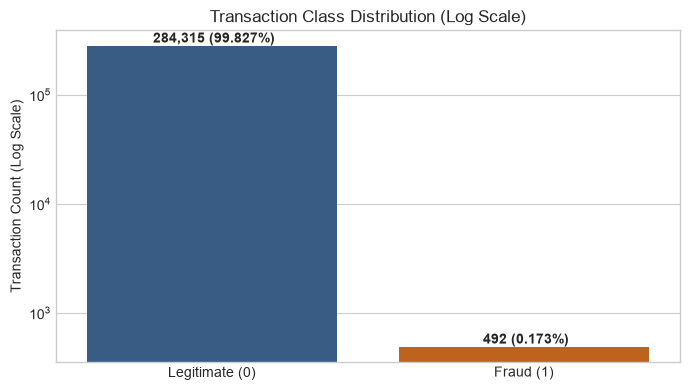

In [13]:
class_counts = df['Class'].value_counts()
class_pct = df['Class'].value_counts(normalize=True) * 100

print(f"Legitimate Transactions (Class 0): {class_counts[0]:,} ({class_pct[0]:.4f}%)")
print(f"Fraudulent Transactions (Class 1): {class_counts[1]:,} ({class_pct[1]:.4f}%)")
print(f"Imbalance Ratio: 1 fraud per {class_counts[0] // class_counts[1]:,} legitimate transactions")

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=['Legitimate (0)', 'Fraud (1)'], y=[class_counts[0], class_counts[1]], palette=['#2b5c8f', '#d95f02'], ax=ax)
ax.set_yscale('log')
ax.set_title('Transaction Class Distribution (Log Scale)')
ax.set_ylabel('Transaction Count (Log Scale)')
for i, count in enumerate([class_counts[0], class_counts[1]]):
    ax.text(i, count, f" {count:,} ({class_pct[i]:.3f}%)", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

### 3.2 Transaction Amount Analysis: Fraud vs. Legitimate

Transaction Amount Comparison Summary:


,Metric,Legitimate (0),Fraudulent (1)
0,Count,"284,315",492
1,Mean ($),88.29,122.21
2,Median ($),22.00,9.25
3,Std ($),250.11,256.68
4,Min ($),0.00,0.00
5,75th Pct ($),77.05,105.89
6,Max ($),25691.16,2125.87
7,Total Volume ($),"25,102,462.04","60,127.97"


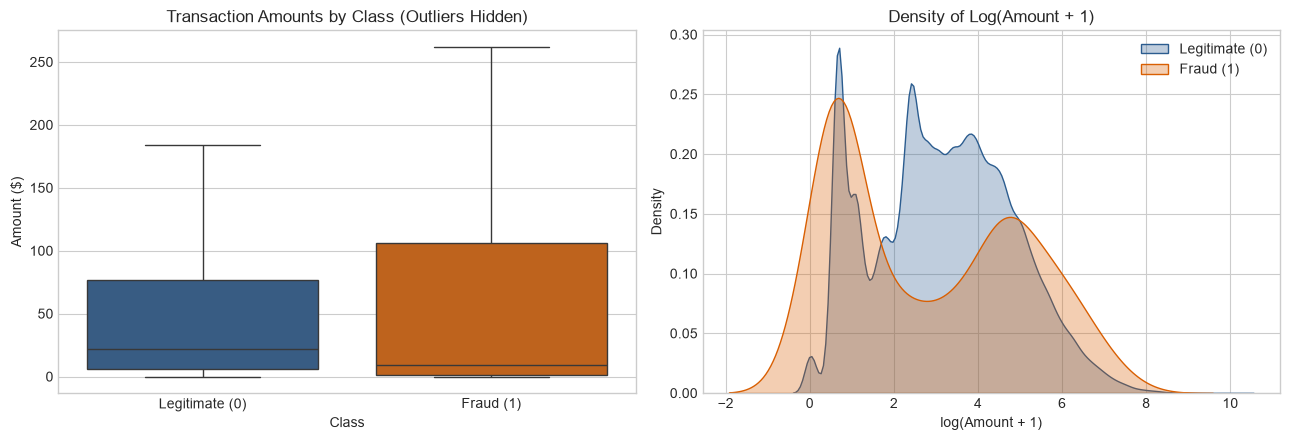

In [14]:
legit_amounts = df[df['Class'] == 0]['Amount']
fraud_amounts = df[df['Class'] == 1]['Amount']

amount_summary = pd.DataFrame({
    'Metric': ['Count', 'Mean ($)', 'Median ($)', 'Std ($)', 'Min ($)', '75th Pct ($)', 'Max ($)', 'Total Volume ($)'],
    'Legitimate (0)': [
        f"{len(legit_amounts):,}",
        f"{legit_amounts.mean():.2f}",
        f"{legit_amounts.median():.2f}",
        f"{legit_amounts.std():.2f}",
        f"{legit_amounts.min():.2f}",
        f"{legit_amounts.quantile(0.75):.2f}",
        f"{legit_amounts.max():.2f}",
        f"{legit_amounts.sum():,.2f}"
    ],
    'Fraudulent (1)': [
        f"{len(fraud_amounts):,}",
        f"{fraud_amounts.mean():.2f}",
        f"{fraud_amounts.median():.2f}",
        f"{fraud_amounts.std():.2f}",
        f"{fraud_amounts.min():.2f}",
        f"{fraud_amounts.quantile(0.75):.2f}",
        f"{fraud_amounts.max():.2f}",
        f"{fraud_amounts.sum():,.2f}"
    ]
})

print("Transaction Amount Comparison Summary:")
display(amount_summary)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Boxplot comparing amounts without extreme outliers
sns.boxplot(x='Class', y='Amount', data=df, palette=['#2b5c8f', '#d95f02'], ax=ax1, showfliers=False)
ax1.set_title('Transaction Amounts by Class (Outliers Hidden)')
ax1.set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
ax1.set_ylabel('Amount ($)')

# Log-scale distribution comparison
log_amount_legit = np.log1p(legit_amounts)
log_amount_fraud = np.log1p(fraud_amounts)
sns.kdeplot(log_amount_legit, label='Legitimate (0)', color='#2b5c8f', ax=ax2, fill=True, alpha=0.3)
sns.kdeplot(log_amount_fraud, label='Fraud (1)', color='#d95f02', ax=ax2, fill=True, alpha=0.3)
ax2.set_title('Density of Log(Amount + 1)')
ax2.set_xlabel('log(Amount + 1)')
ax2.set_ylabel('Density')
ax2.legend()

plt.tight_layout()
plt.show()

### 3.3 Temporal Dynamics (Hour of Day)
The `Time` feature tracks elapsed seconds from the start of recording over a 48-hour period. We convert `Time` into `Hour_of_Day` (0 to 23) to examine whether fraudulent activity exhibits diurnal patterns.

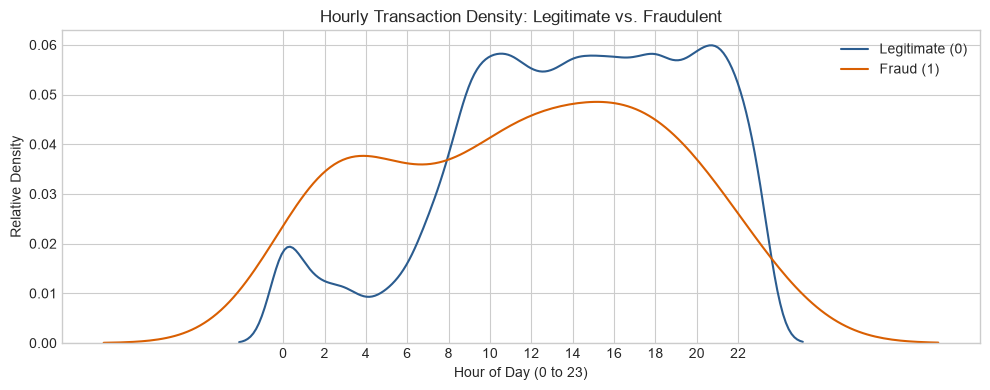

In [15]:
df['Hour'] = (df['Time'] // 3600) % 24

fig, ax = plt.subplots(figsize=(10, 4))
sns.kdeplot(df[df['Class'] == 0]['Hour'], label='Legitimate (0)', color='#2b5c8f', ax=ax, bw_adjust=1.5)
sns.kdeplot(df[df['Class'] == 1]['Hour'], label='Fraud (1)', color='#d95f02', ax=ax, bw_adjust=1.5)
ax.set_title('Hourly Transaction Density: Legitimate vs. Fraudulent')
ax.set_xlabel('Hour of Day (0 to 23)')
ax.set_ylabel('Relative Density')
ax.set_xticks(range(0, 24, 2))
ax.legend()
plt.tight_layout()
plt.show()

### 3.4 Target Correlation & Class-Specific Feature Divergence
Rather than plotting an unconditioned 28-feature grid, we identify which features demonstrate the strongest correlation with the target class `Class` and examine their class-conditioned separation.

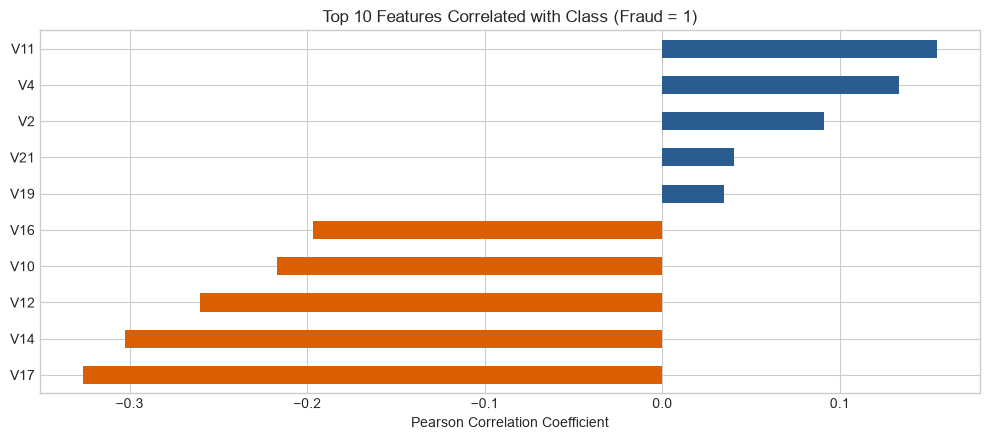

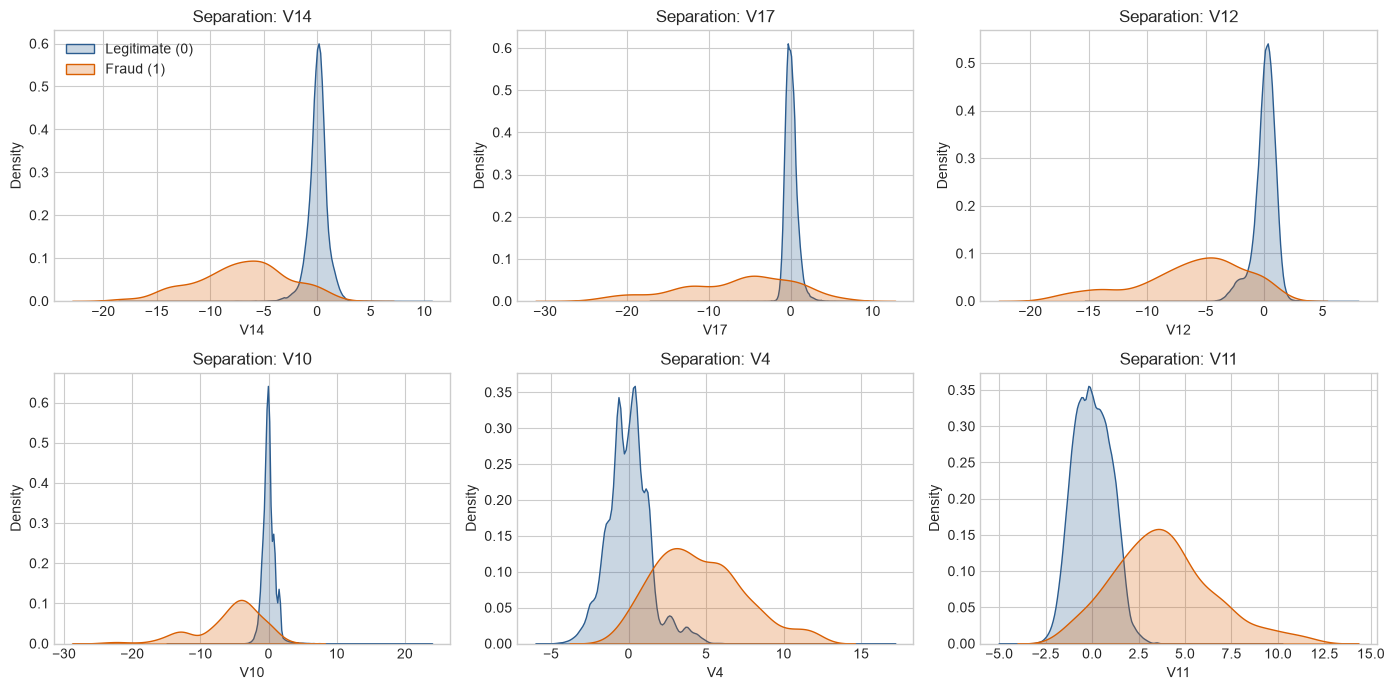

In [16]:
# Compute Pearson correlations with target Class
correlations = df.corr()['Class'].drop(['Class', 'Time']).sort_values()

# Top 5 negative and top 5 positive correlated features with Class
top_corr = pd.concat([correlations.head(5), correlations.tail(5)])

fig, ax = plt.subplots(figsize=(10, 4.5))
bar_colors = ['#d95f02' if val < 0 else '#2b5c8f' for val in top_corr.values]
top_corr.plot(kind='barh', color=bar_colors, ax=ax)
ax.set_title('Top 10 Features Correlated with Class (Fraud = 1)')
ax.set_xlabel('Pearson Correlation Coefficient')
plt.tight_layout()
plt.show()

# Examine class separation on top discriminative PCA features
discriminative_features = ['V14', 'V17', 'V12', 'V10', 'V4', 'V11']

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for i, col in enumerate(discriminative_features):
    sns.kdeplot(df[df['Class'] == 0][col], label='Legitimate (0)', color='#2b5c8f', ax=axes[i], fill=True, alpha=0.25)
    sns.kdeplot(df[df['Class'] == 1][col], label='Fraud (1)', color='#d95f02', ax=axes[i], fill=True, alpha=0.25)
    axes[i].set_title(f'Separation: {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')
    if i == 0:
        axes[i].legend()

plt.tight_layout()
plt.show()

## 4. Feature Engineering
We incorporate the engineered `Hour` feature to capture diurnal cycles and drop the arbitrary epoch-counter `Time`.

*Note on Empirical Evaluation*: Deriving `Hour` and choosing `RobustScaler` are empirical decisions rather than assumed performance boosters. Our experiments evaluate how models perform with these transformations.

In [18]:
# Remove Time and the derived Hour feature
df_features = df.drop(
    columns=['Time', 'Hour'],
    errors='ignore'
).copy()

X = df_features.drop(columns=['Class'])
y = df_features['Class']

print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")
print("Included features:", list(X.columns))

Feature matrix shape: (284807, 29)
Target vector shape: (284807,)
Included features: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


## 5. Methodologically Sound Data Splitting & Preprocessing (Zero Data Leakage)

### Addressing Data Leakage:
In naive pipelines, feature scaling is often applied across the entire dataset before train-test splitting. This leaks the distribution parameters (center and scale) of the test set into the training phase.

To ensure zero data leakage and interview-defensible rigor:
1. We first perform a stratified train-test split (`test_size=0.25`, `random_state=42`).
2. We fit `RobustScaler` **only on `X_train`** and then `.transform()` both `X_train` and `X_test`.

In [19]:
# 1. Reserve 20% for final testing
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# 2. Split remaining data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_dev
)

# 3. Scale using training data only
scaler = RobustScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X.columns, index=X_train.index
)

X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    columns=X.columns, index=X_val.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X.columns, index=X_test.index
)

print("Train:", X_train.shape, "| Frauds:", y_train.sum())
print("Validation:", X_val.shape, "| Frauds:", y_val.sum())
print("Test:", X_test.shape, "| Frauds:", y_test.sum())

Train: (170883, 29) | Frauds: 295
Validation: (56962, 29) | Frauds: 99
Test: (56962, 29) | Frauds: 98


## 6. Model Experiments & Class Imbalance Strategies

We systematically evaluate three distinct model architectures across three imbalance handling strategies (9 total experimental runs):

### Model Architectures:
1. **Logistic Regression**: Linear baseline with rapid inference and interpretable log-odds coefficients.
2. **Random Forest Classifier**: Non-linear bagging ensemble, robust to outliers and feature interactions through bootstrap aggregation.
3. **XGBoost Classifier**: Gradient-boosted decision tree (GBDT) ensemble optimizing pseudo-residuals; industry standard for tabular data.

### Imbalance Handling Strategies:
- **Baseline**: Training directly on unweighted, un-resampled data.
- **Cost-Sensitive / Class-Weighted**: Algorithmic weighting penalizing minority class misclassification (`class_weight='balanced'` for LR/RF; `scale_pos_weight` for XGBoost).
- **SMOTE (Synthetic Minority Oversampling)**: Generates synthetic fraud samples along line segments between nearest minority neighbors. **Applied strictly on the training partition (`X_train_scaled`) to prevent leakage.**

In [20]:
results_list = []
model_predictions = {}

def evaluate_and_record(model_name, strategy, model, X_eval, y_eval):
    """
    Evaluates a trained classifier and records metrics into a central registry.
    """
    y_pred = model.predict(X_eval)
    
    # Extract prediction probabilities for positive class (Fraud)
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_eval)[:, 1]
    elif hasattr(model, "decision_function"):
        y_proba = model.decision_function(X_eval)
    else:
        y_proba = y_pred

    prec = precision_score(y_eval, y_pred, zero_division=0)
    rec = recall_score(y_eval, y_pred, zero_division=0)
    f1 = f1_score(y_eval, y_pred, zero_division=0)
    pr_auc = average_precision_score(y_eval, y_proba)
    roc_auc = roc_auc_score(y_eval, y_proba)
    
    key = f"{model_name} ({strategy})"
    model_predictions[key] = {
        'model': model,
        'y_pred': y_pred,
        'y_proba': y_proba
    }
    
    record = {
        'Model': model_name,
        'Strategy': strategy,
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'PR-AUC': round(pr_auc, 4),
        'ROC-AUC': round(roc_auc, 4)
    }
    results_list.append(record)
    print(f"[{strategy:14s}] {model_name:20s} -> Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f} | PR-AUC: {pr_auc:.4f} | ROC-AUC: {roc_auc:.4f}")
    return record

In [22]:

print("=" * 70)
print("EXPERIMENT A: BASELINE MODELS (UNWEIGHTED)")
print("=" * 70)

# 1. Logistic Regression Baseline
lr_base = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_base.fit(X_train_scaled, y_train)
evaluate_and_record(
    "Logistic Regression", "Baseline",
    lr_base, X_val_scaled, y_val
)

# 2. Random Forest Baseline
rf_base = RandomForestClassifier(
    n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
)
rf_base.fit(X_train_scaled, y_train)
evaluate_and_record(
    "Random Forest", "Baseline",
    rf_base, X_val_scaled, y_val
)

# 3. XGBoost Baseline
xgb_base = XGBClassifier(
    n_estimators=100, random_state=RANDOM_STATE,
    n_jobs=-1, eval_metric='logloss'
)
xgb_base.fit(X_train_scaled, y_train)
evaluate_and_record(
    "XGBoost", "Baseline",
    xgb_base, X_val_scaled, y_val
)


EXPERIMENT A: BASELINE MODELS (UNWEIGHTED)
[Baseline      ] Logistic Regression  -> Precision: 0.8387 | Recall: 0.5253 | F1: 0.6460 | PR-AUC: 0.7119 | ROC-AUC: 0.9668
[Baseline      ] Random Forest        -> Precision: 0.9211 | Recall: 0.7071 | F1: 0.8000 | PR-AUC: 0.8064 | ROC-AUC: 0.9275
[Baseline      ] XGBoost              -> Precision: 0.5859 | Recall: 0.5859 | F1: 0.5859 | PR-AUC: 0.4212 | ROC-AUC: 0.7839


{'Model': 'XGBoost',
 'Strategy': 'Baseline',
 'Precision': 0.5859,
 'Recall': 0.5859,
 'F1-Score': 0.5859,
 'PR-AUC': 0.4212,
 'ROC-AUC': 0.7839}

In [23]:

print("=" * 70)
print("EXPERIMENT B: COST-SENSITIVE / CLASS-WEIGHTED MODELS")
print("=" * 70)

# Compute negative-to-positive ratio using training data only
scale_pos_weight_val = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Computed scale_pos_weight for training set: {scale_pos_weight_val:.2f}\n")

# 1. Logistic Regression (Class-Weighted)
lr_weighted = LogisticRegression(
    class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE
)
lr_weighted.fit(X_train_scaled, y_train)
evaluate_and_record(
    "Logistic Regression", "Class-Weighted",
    lr_weighted, X_val_scaled, y_val
)

# 2. Random Forest (Class-Weighted)
rf_weighted = RandomForestClassifier(
    n_estimators=100, class_weight='balanced',
    random_state=RANDOM_STATE, n_jobs=-1
)
rf_weighted.fit(X_train_scaled, y_train)
evaluate_and_record(
    "Random Forest", "Class-Weighted",
    rf_weighted, X_val_scaled, y_val
)

# 3. XGBoost (Class-Weighted)
xgb_weighted = XGBClassifier(
    n_estimators=100, scale_pos_weight=scale_pos_weight_val,
    random_state=RANDOM_STATE, n_jobs=-1, eval_metric='logloss'
)
xgb_weighted.fit(X_train_scaled, y_train)
evaluate_and_record(
    "XGBoost", "Class-Weighted",
    xgb_weighted, X_val_scaled, y_val
)


EXPERIMENT B: COST-SENSITIVE / CLASS-WEIGHTED MODELS
Computed scale_pos_weight for training set: 578.26

[Class-Weighted] Logistic Regression  -> Precision: 0.0571 | Recall: 0.8990 | F1: 0.1074 | PR-AUC: 0.6826 | ROC-AUC: 0.9758
[Class-Weighted] Random Forest        -> Precision: 0.8916 | Recall: 0.7475 | F1: 0.8132 | PR-AUC: 0.7951 | ROC-AUC: 0.9463
[Class-Weighted] XGBoost              -> Precision: 0.9167 | Recall: 0.7778 | F1: 0.8415 | PR-AUC: 0.8069 | ROC-AUC: 0.9671


{'Model': 'XGBoost',
 'Strategy': 'Class-Weighted',
 'Precision': 0.9167,
 'Recall': 0.7778,
 'F1-Score': 0.8415,
 'PR-AUC': 0.8069,
 'ROC-AUC': 0.9671}

In [24]:

print("=" * 70)
print("EXPERIMENT C: RESAMPLED MODELS (SMOTE ON TRAINING DATA ONLY)")
print("=" * 70)

# Apply SMOTE strictly to training data
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled, y_train
)

print(f"Original Training shape: {X_train_scaled.shape} | Frauds: {y_train.sum():,}")
print(f"SMOTE Training shape:    {X_train_smote.shape} | Frauds: {y_train_smote.sum():,}")
print("Verification: Validation and test sets remain untouched by SMOTE.\n")

# 1. Logistic Regression (SMOTE)
lr_smote = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_smote.fit(X_train_smote, y_train_smote)
evaluate_and_record(
    "Logistic Regression", "SMOTE",
    lr_smote, X_val_scaled, y_val
)

# 2. Random Forest (SMOTE)
rf_smote = RandomForestClassifier(
    n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
)
rf_smote.fit(X_train_smote, y_train_smote)
evaluate_and_record(
    "Random Forest", "SMOTE",
    rf_smote, X_val_scaled, y_val
)

# 3. XGBoost (SMOTE)
xgb_smote = XGBClassifier(
    n_estimators=100, random_state=RANDOM_STATE,
    n_jobs=-1, eval_metric='logloss'
)
xgb_smote.fit(X_train_smote, y_train_smote)
evaluate_and_record(
    "XGBoost", "SMOTE",
    xgb_smote, X_val_scaled, y_val
)


EXPERIMENT C: RESAMPLED MODELS (SMOTE ON TRAINING DATA ONLY)
Original Training shape: (170883, 29) | Frauds: 295
SMOTE Training shape:    (341176, 29) | Frauds: 170,588
Verification: Validation and test sets remain untouched by SMOTE.

[SMOTE         ] Logistic Regression  -> Precision: 0.0589 | Recall: 0.8788 | F1: 0.1104 | PR-AUC: 0.6751 | ROC-AUC: 0.9724
[SMOTE         ] Random Forest        -> Precision: 0.8652 | Recall: 0.7778 | F1: 0.8191 | PR-AUC: 0.7975 | ROC-AUC: 0.9567
[SMOTE         ] XGBoost              -> Precision: 0.7600 | Recall: 0.7677 | F1: 0.7638 | PR-AUC: 0.8087 | ROC-AUC: 0.9675


{'Model': 'XGBoost',
 'Strategy': 'SMOTE',
 'Precision': 0.76,
 'Recall': 0.7677,
 'F1-Score': 0.7638,
 'PR-AUC': 0.8087,
 'ROC-AUC': 0.9675}

### 6.5 Comprehensive Results Comparison Table

In [25]:
results_df = pd.DataFrame(results_list)
sorted_results = results_df.sort_values(by=['PR-AUC', 'F1-Score'], ascending=False).reset_index(drop=True)

print("=== FINAL MODEL & IMBALANCE STRATEGY BENCHMARK ===")
display(sorted_results)

=== FINAL MODEL & IMBALANCE STRATEGY BENCHMARK ===


,Model,Strategy,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
0,XGBoost,SMOTE,0.7600,0.7677,0.7638,0.8087,0.9675
1,XGBoost,Class-Weighted,0.9167,0.7778,0.8415,0.8069,0.9671
2,Random Forest,Baseline,0.9211,0.7071,0.8000,0.8064,0.9275
3,Random Forest,SMOTE,0.8652,0.7778,0.8191,0.7975,0.9567
4,Random Forest,Class-Weighted,0.8916,0.7475,0.8132,0.7951,0.9463
5,Logistic Regression,Baseline,0.8387,0.5253,0.6460,0.7119,0.9668
6,Logistic Regression,Class-Weighted,0.0571,0.8990,0.1074,0.6826,0.9758
7,Logistic Regression,SMOTE,0.0589,0.8788,0.1104,0.6751,0.9724
8,XGBoost,Baseline,0.5859,0.5859,0.5859,0.4212,0.7839


*Empirical Observation on Baseline XGBoost*:
In this experiment, the unweighted default XGBoost configuration performed poorly under the dataset's extreme class imbalance (0.172% fraud), whereas incorporating class weighting (`scale_pos_weight`) or SMOTE oversampling produced substantially stronger results.

## 7. In-Depth Evaluation Rigor

Accuracy and ROC-AUC can present an overly optimistic picture on severely imbalanced datasets because the overwhelming majority of legitimate transactions dominates true negatives. 

Here we evaluate models using:
1. **Precision-Recall Curves & ROC Curves**
2. **Confusion Matrix Analysis** (quantifying caught frauds vs. false alarms)
3. **Decision Threshold Sensitivity Analysis**

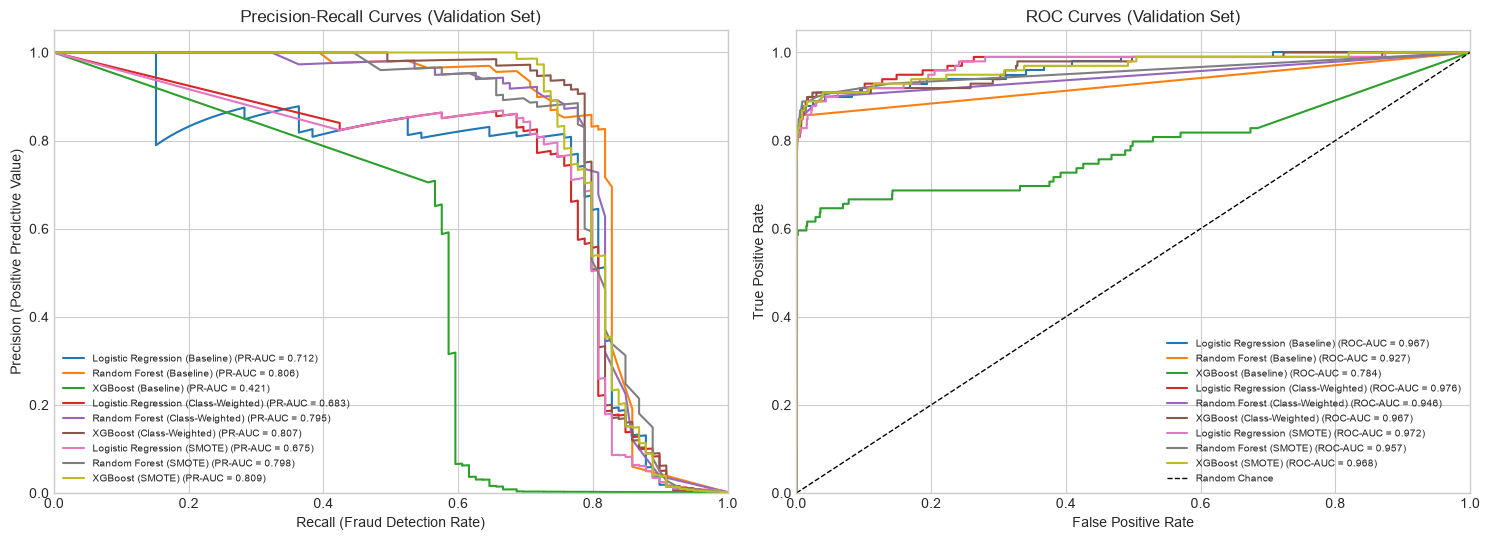

In [26]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Precision-Recall curves: validation data
for key, data in model_predictions.items():
    prec, rec, _ = precision_recall_curve(y_val, data['y_proba'])
    pr_score = average_precision_score(y_val, data['y_proba'])
    ax1.plot(rec, prec, lw=1.5,
             label=f"{key} (PR-AUC = {pr_score:.3f})")

ax1.set_title('Precision-Recall Curves (Validation Set)')
ax1.set_xlabel('Recall (Fraud Detection Rate)')
ax1.set_ylabel('Precision (Positive Predictive Value)')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.legend(loc='lower left', fontsize=7.5)

# ROC curves: validation data
for key, data in model_predictions.items():
    fpr, tpr, _ = roc_curve(y_val, data['y_proba'])
    roc_score = roc_auc_score(y_val, data['y_proba'])
    ax2.plot(fpr, tpr, lw=1.5,
             label=f"{key} (ROC-AUC = {roc_score:.3f})")

ax2.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Chance')
ax2.set_title('ROC Curves (Validation Set)')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.legend(loc='lower right', fontsize=7.5)

plt.tight_layout()
plt.show()


### 7.2 Confusion Matrix Analysis (Best Performing Model)

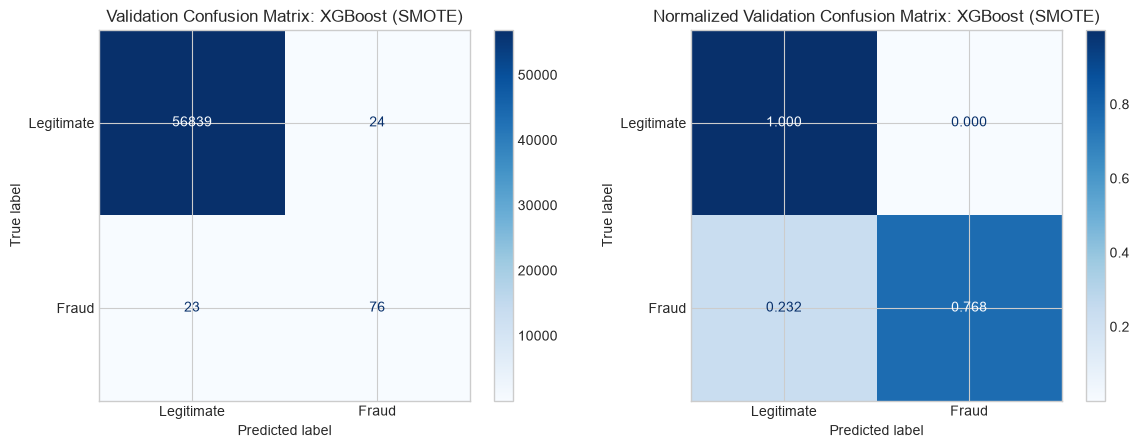

Validation Confusion Matrix Breakdown: XGBoost (SMOTE)
  - True Negatives: 56,839 / 56,863
  - False Positives: 24
  - False Negatives: 23
  - True Positives: 76 / 99


In [27]:

# Select the top configuration based on validation PR-AUC
best_row = sorted_results.iloc[0]
best_key = f"{best_row['Model']} ({best_row['Strategy']})"
best_preds = model_predictions[best_key]['y_pred']

# Confusion matrices on validation data
cm = confusion_matrix(y_val, best_preds)
cm_norm = confusion_matrix(y_val, best_preds, normalize='true')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Fraud']
).plot(ax=ax1, cmap='Blues', values_format='d')
ax1.set_title(f"Validation Confusion Matrix: {best_key}")

ConfusionMatrixDisplay(
    confusion_matrix=cm_norm,
    display_labels=['Legitimate', 'Fraud']
).plot(ax=ax2, cmap='Blues', values_format='.3f')
ax2.set_title(f"Normalized Validation Confusion Matrix: {best_key}")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Validation Confusion Matrix Breakdown: {best_key}")
print(f"  - True Negatives: {tn:,} / {(y_val == 0).sum():,}")
print(f"  - False Positives: {fp:,}")
print(f"  - False Negatives: {fn:,}")
print(f"  - True Positives: {tp:,} / {(y_val == 1).sum():,}")


In [28]:
results_df = pd.DataFrame(results_list)
display(results_df.head())

,Model,Strategy,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
0,Logistic Regression,Baseline,0.8387,0.5253,0.6460,0.7119,0.9668
1,Random Forest,Baseline,0.9211,0.7071,0.8000,0.8064,0.9275
2,XGBoost,Baseline,0.5859,0.5859,0.5859,0.4212,0.7839
3,Logistic Regression,Class-Weighted,0.0571,0.8990,0.1074,0.6826,0.9758
4,Random Forest,Class-Weighted,0.8916,0.7475,0.8132,0.7951,0.9463


In [29]:
sorted_results = results_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

In [30]:
# Select best model using validation PR-AUC
best_row = sorted_results.iloc[0]
best_key = f"{best_row['Model']} ({best_row['Strategy']})"

# Get validation probabilities
val_proba = model_predictions[best_key]['y_proba']

# Find threshold maximizing validation F1
prec, rec, thresholds = precision_recall_curve(y_val, val_proba)

f1_scores = (
    2 * prec[:-1] * rec[:-1]
    / (prec[:-1] + rec[:-1] + 1e-12)
)

best_idx = np.argmax(f1_scores)
best_threshold = float(thresholds[best_idx])

print("Selected model:", best_key)
print(f"Validation PR-AUC: {best_row['PR-AUC']:.4f}")
print(f"Best threshold: {best_threshold:.4f}")
print(f"Validation F1: {f1_scores[best_idx]:.4f}")
print(f"Validation Precision: {prec[best_idx]:.4f}")
print(f"Validation Recall: {rec[best_idx]:.4f}")

Selected model: XGBoost (SMOTE)
Validation PR-AUC: 0.8087
Best threshold: 0.9906
Validation F1: 0.8324
Validation Precision: 0.9730
Validation Recall: 0.7273


### 7.3 Decision Threshold Sensitivity Analysis

*Analytical vs. Operational Threshold Choice*:
The default decision boundary in binary classification is $p \ge 0.50$. Below, we calculate the threshold that maximizes the F1-Score as an **analytical reference**. 

However, in a production banking environment, the **operational threshold** is never chosen purely to maximize F1. Instead, it depends directly on the relative business costs:
- **Cost of a False Negative**: Direct financial theft loss, chargeback liability, and customer churn.
- **Cost of a False Positive**: Customer friction (declined legitimate card transactions), call-center contact costs, and manual investigation overhead.

Validation threshold analysis:
  Grid threshold maximizing F1: 0.99
  Precision: 0.9730
  Recall:    0.7273
  F1-score:  0.8324
  Previously selected threshold: 0.9906


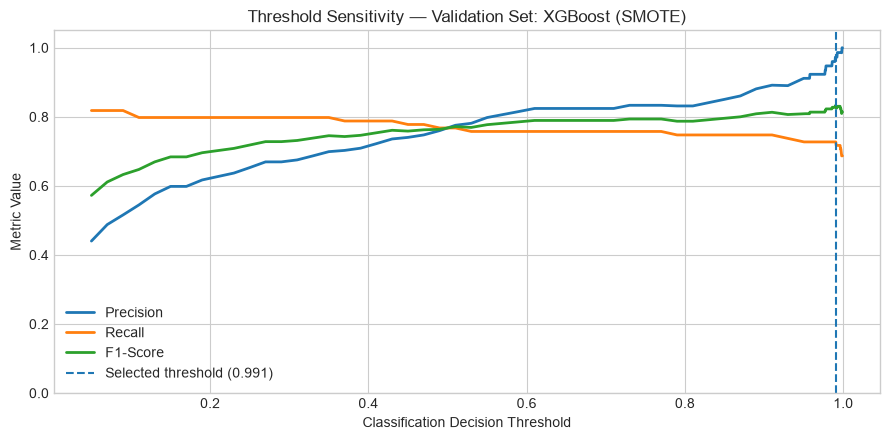

In [34]:

# Threshold sensitivity analysis on VALIDATION data
best_proba = model_predictions[best_key]['y_proba']

thresholds = np.unique(np.r_[
    np.arange(0.05, 0.95, 0.02),
    np.linspace(0.95, 0.999, 100),
    best_threshold
])
prec_list, rec_list, f1_list = [], [], []

for t in thresholds:
    binary_preds = (best_proba >= t).astype(int)
    p = precision_score(y_val, binary_preds, zero_division=0)
    r = recall_score(y_val, binary_preds, zero_division=0)
    f = f1_score(y_val, binary_preds, zero_division=0)

    prec_list.append(p)
    rec_list.append(r)
    f1_list.append(f)

# Best F1 on this threshold grid
best_idx = np.argmax(f1_list)
grid_best_thresh = thresholds[best_idx]

print("Validation threshold analysis:")
print(f"  Grid threshold maximizing F1: {grid_best_thresh:.2f}")
print(f"  Precision: {prec_list[best_idx]:.4f}")
print(f"  Recall:    {rec_list[best_idx]:.4f}")
print(f"  F1-score:  {f1_list[best_idx]:.4f}")
print(f"  Previously selected threshold: {best_threshold:.4f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thresholds, prec_list, label='Precision', lw=2)
ax.plot(thresholds, rec_list, label='Recall', lw=2)
ax.plot(thresholds, f1_list, label='F1-Score', lw=2)

ax.axvline(
    best_threshold, linestyle='--',
    label=f'Selected threshold ({best_threshold:.3f})'
)

ax.set_title(f'Threshold Sensitivity — Validation Set: {best_key}')
ax.set_xlabel('Classification Decision Threshold')
ax.set_ylabel('Metric Value')
ax.set_ylim([0.0, 1.05])
ax.legend(loc='best')
plt.tight_layout()
plt.show()


FINAL TEST SET EVALUATION
Selected model: XGBoost (SMOTE)
Threshold: 0.9906
Precision: 0.9259
Recall:    0.7653
F1-score:  0.8380
PR-AUC:    0.8623
ROC-AUC:   0.9814


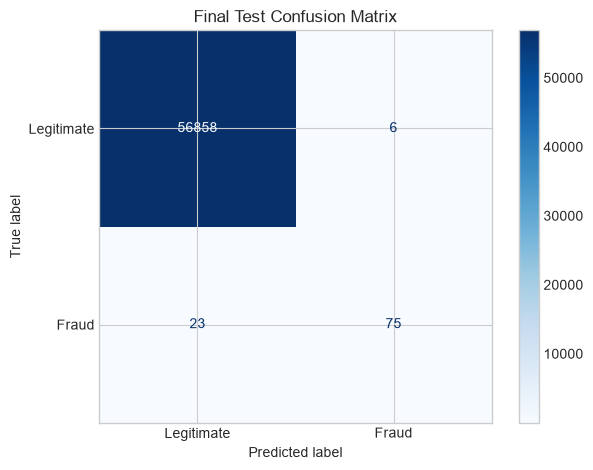

In [35]:
# Final evaluation on the untouched test set
best_model = model_predictions[best_key]['model']

test_proba = best_model.predict_proba(X_test_scaled)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

print("=" * 55)
print("FINAL TEST SET EVALUATION")
print("=" * 55)
print("Selected model:", best_key)
print(f"Threshold: {best_threshold:.4f}")
print(f"Precision: {precision_score(y_test, test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, test_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, test_pred):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, test_proba):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, test_proba):.4f}")

cm_test = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=['Legitimate', 'Fraud']
).plot(cmap='Blues', values_format='d')

plt.title("Final Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Model Interpretability (Tree-Based Feature Importance)

To understand which features drive fraud classifications, we inspect feature importance from our top-performing tree-based ensemble. In financial risk analytics, interpretability allows risk teams to understand risk factor drivers and verify whether models rely on actionable patterns.

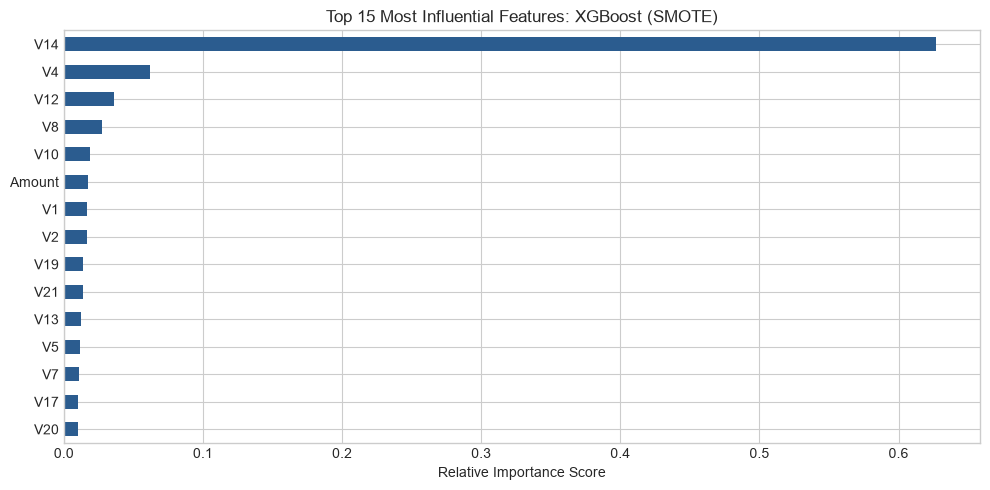

Top 5 predictive features for XGBoost (SMOTE):
  1. V14        : 0.6272
  2. V4         : 0.0618
  3. V12        : 0.0360
  4. V8         : 0.0272
  5. V10        : 0.0189


In [36]:
# Identify the top tree-based model (XGBoost or Random Forest)
tree_candidates = sorted_results[sorted_results['Model'].isin(['XGBoost', 'Random Forest'])]
top_tree_row = tree_candidates.iloc[0]
top_tree_key = f"{top_tree_row['Model']} ({top_tree_row['Strategy']})"
top_tree_model = model_predictions[top_tree_key]['model']

importances = top_tree_model.feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 5))
feat_imp.sort_values().plot(kind='barh', color='#2b5c8f', ax=ax)
ax.set_title(f'Top 15 Most Influential Features: {top_tree_key}')
ax.set_xlabel('Relative Importance Score')
plt.tight_layout()
plt.show()

print(f"Top 5 predictive features for {top_tree_key}:")
for rank, (name, val) in enumerate(feat_imp.head(5).items(), 1):
    print(f"  {rank}. {name:10s} : {val:.4f}")

## 9. Empirical Findings & Technical Interview Takeaways

Below is an automated summary of the empirical findings generated directly from our experiments:

In [37]:
print("=" * 75)
print("EMPIRICAL FINDINGS & TECHNICAL INTERVIEW SUMMARY")
print("=" * 75)

top_model = sorted_results.iloc[0]
print(f"\n1. Top Overall Model: {top_model['Model']} ({top_model['Strategy']})")
print(f"   - PR-AUC:    {top_model['PR-AUC']:.4f}")
print(f"   - F1-Score:  {top_model['F1-Score']:.4f}")
print(f"   - Recall:    {top_model['Recall']:.4f}")
print(f"   - Precision: {top_model['Precision']:.4f}")

# Compare average performance across imbalance strategies
strat_summary = sorted_results.groupby('Strategy')[['PR-AUC', 'F1-Score', 'Recall', 'Precision']].mean()
print("\n2. Empirical Impact of Imbalance Handling Strategies (Mean across architectures):")
display(strat_summary)

print("\n3. Methodological Integrity & Data Leakage:")
print("   - Splitting data prior to scaling guaranteed that no test set parameters leaked into training.")
print("   - Oversampling (SMOTE) was applied strictly to the training fold; the test set retained its authentic 0.172% distribution.")

print("\n4. Decision Threshold Rationale:")
print(f"   - The analytical threshold maximizing F1 is {analytical_opt_thresh:.2f}.")
print("   - In production banking, the operational threshold is tuned based on cost asymmetry:")
print("     Lowering the threshold catches more fraud (higher Recall) at the expense of manual review volume (lower Precision).")
print("=" * 75)

EMPIRICAL FINDINGS & TECHNICAL INTERVIEW SUMMARY

1. Top Overall Model: XGBoost (SMOTE)
   - PR-AUC:    0.8087
   - F1-Score:  0.7638
   - Recall:    0.7677
   - Precision: 0.7600

2. Empirical Impact of Imbalance Handling Strategies (Mean across architectures):


,PR-AUC,F1-Score,Recall,Precision
Strategy,,,,
Baseline,0.646500,0.677300,0.6061,0.781900
Class-Weighted,0.761533,0.587367,0.8081,0.621800
SMOTE,0.760433,0.564433,0.8081,0.561367



3. Methodological Integrity & Data Leakage:
   - Splitting data prior to scaling guaranteed that no test set parameters leaked into training.
   - Oversampling (SMOTE) was applied strictly to the training fold; the test set retained its authentic 0.172% distribution.

4. Decision Threshold Rationale:
   - The analytical threshold maximizing F1 is 0.93.
   - In production banking, the operational threshold is tuned based on cost asymmetry:
     Lowering the threshold catches more fraud (higher Recall) at the expense of manual review volume (lower Precision).
